# Week 9 – LLM Prompting and Structured Output
## Customer Review Intelligence System

This notebook teaches and implements the Week 9 assignment using **Google Gemini API, Python and Pydantic**.

**Learning outcome:** Write clear prompts, use few-shot examples, request schemas and validate outputs.

**Assignment:** Build a 20-case prompt test set, compare two prompts and log failures.

**Success criteria:** Measure valid schema rate and connect prompt changes to observed failures.

### How to use this notebook
1. Open the notebook in Google Colab.
2. Add your Gemini API key to Colab **Secrets** using the exact name `GOOGLE_API_KEY`.
3. Run cells from top to bottom.
4. First verify the API with one request. Only then run the full evaluation.
5. The Prompt A/B comparison makes 40 real API calls. Prompt C makes another 20. API usage may incur charges or rate limits.

**Teaching format:** Each code cell is accompanied by a concept explanation and an output-analysis section. Gemini responses and evaluation scores are live results and can vary. No mock results are used for the actual evaluation.

## SECTION 1 – Introduction to LLMs

### Concept Explanation
Before writing code, let's understand the landscape of AI:
* **Artificial Intelligence (AI)**: The broad field of creating machines capable of mimicking human cognitive tasks (e.g., learning, reasoning, pattern matching).
* **Generative AI (GenAI)**: A subset of AI focused on *generating* new content (text, images, audio, code) rather than merely classifying or predicting data.
* **Large Language Models (LLMs)**: Advanced GenAI models trained on massive text corpora to predict the next word (token) in a sequence.
* **Tokens**: The basic units of text processed by an LLM. A token is not always a full word; it is often a sub-word (roughly 4 characters of English text = 1 token).
* **Context Window**: The maximum amount of text (tokens) a model can receive and generate in a single interaction. Think of it as the model's active short-term memory.
* **Prompt Engineering**: The discipline of designing, crafting, and refining instructions (prompts) to guide an LLM to generate precise, reliable, and context-aware responses.

### Why Do We Need This?
Unlike traditional programming where you write rules (`if/else` logic) to map inputs to outputs, LLM-based development utilizes natural language instructions. This allows us to handle complex, fuzzy unstructured text (like customer feedback) with remarkable flexibility. However, it introduces non-determinism, which prompt engineering and structured validation solve.

### Comparison of Major Frontier LLM Families
| Model Family | Primary Developer | Primary Use Cases | Key Strength |
| :--- | :--- | :--- | :--- |
| **Gemini** | Google | Multimodal tasks, massive context windows, structured parsing | Advanced reasoning & direct schema constraints |
| **GPT** | OpenAI | General reasoning, conversational agents, code generation | Extremely broad ecosystem & tool use |
| **Claude** | Anthropic | Long-context analysis, complex coding, high-fidelity writing | Exceptional nuance & safety alignment |
| **Llama** | Meta | Open-weights custom deployment, local execution | Portability and cost control |

## SECTION 2 – Prompt Engineering Fundamentals

### Concept Explanation
An effective prompt acts as a detailed specifications document for the LLM. Rather than simply asking the model to "analyze this," professional prompt engineers structure prompts using **five core components**:
1. **Role**: Defining *who* the model is (e.g., "You are a senior customer success manager"). This aligns the model's internal statistical weights to a specific domain.
2. **Context**: Providing relevant background information or situational constraints.
3. **Task**: Highlighting the explicit actions the model must perform.
4. **Constraints**: Listing boundaries (e.g., "Do not include introductory or concluding text").
5. **Output Format**: Defining how the results should look (e.g., "Output must be valid JSON matching this schema").

### Implementation
Let's write a small Python script illustrating a bad prompt versus an optimized prompt, showing why structure works better.

In [1]:
# Comparing Bad Prompting to Structured Component-based Prompting
bad_prompt = "Check this review and tell me what they think: 'The display of this tablet is gorgeous, but it is way too heavy.'"

optimized_prompt = """
Role: You are an expert Product Quality Analyst.
Context: We are analyzing customer reviews for our newly launched tablet to identify product flaws.
Task: Categorize the overall sentiment and isolate specific feedback about the hardware.
Constraints: Output exactly 2 bullet points. Do not write any conversational intro.
Review to analyze: 'The display of this tablet is gorgeous, but it is way too heavy.'
Output Format:
- Sentiment: [Positive/Negative/Mixed]
- HW Detail: [Feature isolated]
"""

print("=== BAD PROMPT EXAMPLE ===")
print(bad_prompt)
print("\n=== OPTIMIZED PROMPT EXAMPLE ===")
print(optimized_prompt)

=== BAD PROMPT EXAMPLE ===
Check this review and tell me what they think: 'The display of this tablet is gorgeous, but it is way too heavy.'

=== OPTIMIZED PROMPT EXAMPLE ===

Role: You are an expert Product Quality Analyst.
Context: We are analyzing customer reviews for our newly launched tablet to identify product flaws.
Task: Categorize the overall sentiment and isolate specific feedback about the hardware.
Constraints: Output exactly 2 bullet points. Do not write any conversational intro.
Review to analyze: 'The display of this tablet is gorgeous, but it is way too heavy.'
Output Format:
- Sentiment: [Positive/Negative/Mixed]
- HW Detail: [Feature isolated]



### Output Analysis
The optimized prompt gives the LLM zero room for ambiguity. By specifying the role, the task, constraints, and exact output format, we drastically minimize unstructured filler text (such as "Sure, here is the analysis:"), making the downstream parsing process highly reliable.

## SECTION 3 – Zero-shot, One-shot and Few-shot Prompting

### Concept Explanation
* **Zero-shot Prompting**: Asking the LLM to complete a task without providing any illustrative examples. This tests the model's raw pre-trained knowledge.
* **One-shot Prompting**: Providing exactly one complete example of the input and expected output before presenting the actual task. This helps standardise output formatting.
* **Few-shot Prompting**: Providing multiple (usually 3 or more) high-quality examples of inputs and their corresponding structured outputs. This is extremely powerful for complex tasks, Edge-cases, or niche data structures.

### Implementation
Let's construct variables representing all three strategies targeting the exact same review, so you can see how their complexities differ.

In [2]:
test_review = "The food arrived cold, but the delivery driver was incredibly polite."

zero_shot_prompt = f"""
Analyze the following customer review and determine the sentiment:
Review: "{test_review}"
Sentiment:
"""

one_shot_prompt = f"""
Analyze the following customer review and determine the sentiment.

Example:
Review: "The camera takes beautiful portraits, but the physical button fell off within an hour."
Sentiment: Mixed

Now perform the same task for this review:
Review: "{test_review}"
Sentiment:
"""

few_shot_prompt = f"""
Analyze the following customer review and determine the sentiment.

Example 1:
Review: "I absolutely love this new coffee machine!"
Sentiment: Positive

Example 2:
Review: "The customer support was rude and unresolved."
Sentiment: Negative

Example 3:
Review: "The package arrived today."
Sentiment: Neutral

Example 4:
Review: "The laptop has an outstanding screen, but the cooling fan is incredibly loud and annoying."
Sentiment: Mixed

Now perform the same task for this review:
Review: "{test_review}"
Sentiment:
"""

print("--- Zero-Shot Prompt Size:", len(zero_shot_prompt), "characters")
print("--- One-Shot Prompt Size:", len(one_shot_prompt), "characters")
print("--- Few-Shot Prompt Size:", len(few_shot_prompt), "characters")

--- Zero-Shot Prompt Size: 159 characters
--- One-Shot Prompt Size: 327 characters
--- Few-Shot Prompt Size: 574 characters


### Output Analysis
As you can see, the prompt size scales significantly as we transition to few-shot prompting. Although it uses more input tokens, the few-shot prompt establishes a highly resilient baseline pattern, ensuring the model understands complex boundary cases (like distinguishing "Mixed" from simple "Negative").

## SECTION 4 – Structured Output and JSON

### Concept Explanation
* **Structured Output**: Forcing the LLM to return data in a predictable format (like JSON) instead of free-form human conversational text. This is critical for programmatic applications.
* **JSON (JavaScript Object Notation)**: A lightweight data-interchange format composed of key-value pairs (Objects) and ordered lists (Arrays).
* **Syntax Validation vs. Schema Validation**:
  - **JSON Syntax Validation**: Verifying that the string is a valid JSON structure (e.g., correct placement of brackets, colons, quotes).
  - **Pydantic Schema Validation**: Verifying that the content inside the valid JSON conforms to specific semantic constraints (e.g., checking that a rating is a number between 0 and 10, or that a sentiment string is one of the allowed categories).

### Implementation
Let's write code to show how we safely convert a raw JSON string into a Python dictionary, including robust error handling using python's `try-except` blocks.

In [3]:
import json

# Simulated raw text output from an LLM representing a JSON structure
raw_llm_json_string = '{"sentiment": "Positive", "confidence": 0.95, "positive_aspect": "Fast shipping"}'

# Simulated corrupt raw text output
corrupted_llm_string = '{"sentiment": "Positive", "confidence": 0.95, "positive_aspect": Fast shipping' # Missing quote and bracket

def parse_raw_json(json_str):
    try:
        parsed_dict = json.loads(json_str)
        print("Successfully parsed JSON!")
        print("Python Dictionary:", parsed_dict)
        return parsed_dict
    except json.JSONDecodeError as e:
        print("JSON Syntax Validation failed!")
        print("Error Message:", e)
        return None

print("=== Parse Case 1 ===")
parse_raw_json(raw_llm_json_string)

print("\n=== Parse Case 2 ===")
parse_raw_json(corrupted_llm_string)

=== Parse Case 1 ===
Successfully parsed JSON!
Python Dictionary: {'sentiment': 'Positive', 'confidence': 0.95, 'positive_aspect': 'Fast shipping'}

=== Parse Case 2 ===
JSON Syntax Validation failed!
Error Message: Expecting value: line 1 column 66 (char 65)


### Output Analysis
The code above demonstrates how easy it is for syntactic mistakes (like missing quotes) to break parsing operations. We must implement validation layers to capture these runtime failure modes before they crash our production systems.

## SECTION 5 – Pydantic and Schema Validation

### Concept Explanation
**Pydantic** is the leading library for data parsing and validation in Python. It enforces type hints at runtime, throwing user-friendly validation errors when the data doesn't match the schema rules. Let's design a custom schema representing customer sentiment metrics:

* `sentiment`: Must be restricted to specific values: Positive, Negative, Neutral, Mixed (enforced using python `Literal`).
* `confidence`: Float rating between 0.0 and 1.0 (enforced using `Field(ge=0, le=1)`).
* `positive_aspect`: String description.
* `negative_aspect`: String description.
* `reason`: String describing why the sentiment was selected.

### Implementation
Let's implement this validation schema and write multiple test configurations representing perfect data, wrong data types, and constraint violations.

In [4]:
from typing import Literal, Optional
from pydantic import BaseModel, Field, ValidationError

# Define the target schema
class ReviewAnalysis(BaseModel):
    sentiment: Literal["Positive", "Negative", "Neutral", "Mixed"]
    confidence: float = Field(ge=0.0, le=1.0, description="The model's confidence rating.")
    positive_aspect: Optional[str] = Field(default="None", description="Extracted positive features or features.")
    negative_aspect: Optional[str] = Field(default="None", description="Extracted negative concerns or issues.")
    reason: str = Field(description="Justification for classification.")

# Test payloads
valid_payload = {
    "sentiment": "Mixed",
    "confidence": 0.85,
    "positive_aspect": "High-definition screen",
    "negative_aspect": "Terrible battery drain",
    "reason": "User was polarized on screen quality vs battery life."
}

invalid_sentiment_payload = {
    "sentiment": "Awesome", # Not in literal
    "confidence": 0.85,
    "positive_aspect": "High-definition screen",
    "negative_aspect": "Terrible battery drain",
    "reason": "Invalid category test."
}

out_of_bounds_confidence_payload = {
    "sentiment": "Positive",
    "confidence": 12.5, # Exceeds maximum boundary of 1.0
    "positive_aspect": "None",
    "negative_aspect": "None",
    "reason": "Invalid confidence bounds test."
}

def validate_payload(payload):
    try:
        validated = ReviewAnalysis.model_validate(payload)
        print("Success! Validated data:", validated.model_dump())
        return validated
    except ValidationError as e:
        print("Pydantic Validation failed with standard errors:")
        for error in e.errors():
            print(f" - Field: {error['loc'][0]} | Error: {error['msg']}")
        return None

print("=== Payload 1: Perfect payload ===")
validate_payload(valid_payload)

print("\n=== Payload 2: Invalid Sentiment ===")
validate_payload(invalid_sentiment_payload)

print("\n=== Payload 3: Out-of-bounds Confidence ===")
validate_payload(out_of_bounds_confidence_payload)

=== Payload 1: Perfect payload ===
Success! Validated data: {'sentiment': 'Mixed', 'confidence': 0.85, 'positive_aspect': 'High-definition screen', 'negative_aspect': 'Terrible battery drain', 'reason': 'User was polarized on screen quality vs battery life.'}

=== Payload 2: Invalid Sentiment ===
Pydantic Validation failed with standard errors:
 - Field: sentiment | Error: Input should be 'Positive', 'Negative', 'Neutral' or 'Mixed'

=== Payload 3: Out-of-bounds Confidence ===
Pydantic Validation failed with standard errors:
 - Field: confidence | Error: Input should be less than or equal to 1


### Output Analysis
Pydantic acts as an impenetrable gatekeeper. Even if the incoming data is syntactically correct JSON, the schema validator successfully catches bad categories ("Awesome") and out-of-bounds metrics (confidence "12.5"), ensuring downstream pipelines receive consistent data objects.

## SECTION 6 – Gemini API Integration

### Concept Explanation
- **API (Application Programming Interface):** A way for one program to request a service from another program.
- **SDK (Software Development Kit):** A library that makes API requests easier from a programming language.
- **API key:** A credential that authorizes requests.
- **Temperature:** A generation setting that influences randomness. A lower value generally gives more consistent output, but does not guarantee correctness.

We will use Google's current `google-genai` Python SDK and the real Gemini API. We will not silently fall back to mock responses because mock outputs would make the evaluation metrics misleading.

### Before running
In Google Colab, open the Secrets panel (key icon), add a secret named `GOOGLE_API_KEY`, paste your Gemini API key, and enable notebook access.

In [7]:

# ============================================================
# CELL 1: INSTALL LIBRARIES AND INITIALIZE GEMINI
# ============================================================

# Install compatible dependencies without unnecessarily
# upgrading all the preinstalled Google Colab packages.

%pip install -q "google-genai>=2.12.1,<3" "google-auth==2.49.0" "pandas==2.2.3" "bottleneck>=1.5.0"

# ------------------------------------------------------------
# 1. IMPORT REQUIRED LIBRARIES
# ------------------------------------------------------------

from google import genai
from google.colab import userdata

import json
import time
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from typing import Literal, Optional

from pydantic import BaseModel, Field, ValidationError

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
    classification_report
)

# ------------------------------------------------------------
# 2. RETRIEVE GEMINI API KEY SECURELY
# ------------------------------------------------------------

# GOOGLE_API_KEY must be stored in Colab Secrets.
# Never print or expose your API key.

api_key = userdata.get("GOOGLE_API_KEY")

if not api_key:
    raise ValueError(
        "GOOGLE_API_KEY not found. "
        "Add it in Colab Secrets and enable notebook access."
    )

# ------------------------------------------------------------
# 3. INITIALIZE GEMINI CLIENT
# ------------------------------------------------------------

client = genai.Client(api_key=api_key)

print("Required libraries imported successfully.")
print("Gemini API client initialized successfully.")
print("API key was retrieved securely.")


Required libraries imported successfully.
Gemini API client initialized successfully.
API key was retrieved securely.


### Output Analysis
- `%pip install` installs the SDK and supporting packages in the Colab runtime.
- The imports load the functions used in the rest of the notebook.
- `userdata.get("GOOGLE_API_KEY")` retrieves the secret without exposing it in notebook output.
- `genai.Client(api_key=api_key)` creates the real API client.

**Expected output:** Confirmation that libraries were imported and the Gemini client was initialized.

If this cell fails, check the secret name, its value and whether notebook access is enabled. Do not continue until the client is initialized. If the Colab runtime restarts, rerun the notebook from the beginning because variables are cleared.

### Model discovery and connection test

Model availability can differ by API key and can change over time. We query the models available to your account and select only a model that advertises `generateContent`.

The preferred model is used only if it is actually listed. Otherwise, the code selects the first available generation model. It does not silently use an unverified fallback.

In [11]:

# ============================================================
# CELL 2: MODEL DISCOVERY, RETRY AND AUTOMATIC FALLBACK
# ============================================================

import time

print("Fetching available models...")

# ------------------------------------------------------------
# 1. DISCOVER MODELS
# ------------------------------------------------------------

models_list = list(client.models.list())

candidate_models = []

for model in models_list:

    supported_actions = getattr(
        model,
        "supported_actions",
        []
    ) or []

    if "generateContent" in supported_actions:

        model_name = model.name.replace("models/", "")

        candidate_models.append(model_name)

if not candidate_models:
    raise RuntimeError(
        "No models supporting generateContent were found."
    )

print(f"\nFound {len(candidate_models)} generation model(s).")

# ------------------------------------------------------------
# 2. DEFINE MODEL PRIORITY
# ------------------------------------------------------------

# Try these models in this order.
# The first available and working model will be selected.

PREFERRED_MODELS = [
    "gemini-3.8-flash",
    "gemini-3.7-flash",
    "gemini-3.6-flash",
    "gemini-3.5-flash",
    "gemini-3.1-flash-lite",
    "gemini-2.5-flash-lite",
    "gemini-2.5-flash",
    "gemini-2.5-pro"
]

# Keep only models that were actually returned by the API.
ordered_models = [
    model for model in PREFERRED_MODELS
    if model in candidate_models
]

# Add any remaining text-generation models as additional fallbacks.
remaining_models = [
    model for model in candidate_models
    if model not in ordered_models
    and "-image" not in model
    and "deep-research" not in model
]

ordered_models.extend(remaining_models)

print("\nModels that will be tested:")

for model_name in ordered_models:
    print("-", model_name)

# ------------------------------------------------------------
# 3. TEST MODELS WITH AUTOMATIC RETRIES
# ------------------------------------------------------------

SELECTED_MODEL = None
test_response = None

MAX_ATTEMPTS = 2

for model_name in ordered_models:

    print(f"\nTrying model: {model_name}")

    for attempt in range(1, MAX_ATTEMPTS + 1):

        try:

            test_response = client.models.generate_content(

                model=model_name,

                contents=(
                    "Explain sentiment analysis "
                    "in two simple sentences."
                )
            )

            if not test_response.text:
                raise ValueError(
                    "The model returned an empty response."
                )

            # Save the first successfully tested model.
            SELECTED_MODEL = model_name

            print("\nGemini connection test successful!")
            print("Selected model:", SELECTED_MODEL)

            print("\nModel response:")
            print(test_response.text)

            break

        except Exception as e:

            error_message = str(e)

            print(
                f"Attempt {attempt}/{MAX_ATTEMPTS} failed."
            )

            print("Error:", error_message)

            # Identify temporary server/rate-limit errors.
            temporary_error = any(
                code in error_message
                for code in [
                    "503",
                    "UNAVAILABLE",
                    "429",
                    "RESOURCE_EXHAUSTED",
                    "500",
                    "INTERNAL",
                    "504",
                    "DEADLINE_EXCEEDED"
                ]
            )

            if temporary_error:

                if attempt < MAX_ATTEMPTS:

                    wait_seconds = 3 * attempt

                    print(
                        f"Temporary issue. Retrying "
                        f"after {wait_seconds} seconds..."
                    )

                    time.sleep(wait_seconds)

                else:

                    print(
                        "Model unavailable after retries. "
                        "Trying the next model..."
                    )

            else:

                # Non-temporary model-specific errors:
                # move to the next candidate.
                print(
                    "This model could not be used. "
                    "Trying the next model..."
                )

                break

    # Stop trying other models after a successful response.
    if SELECTED_MODEL is not None:
        break

# ------------------------------------------------------------
# 4. FINAL STATUS
# ------------------------------------------------------------

if SELECTED_MODEL is None:

    raise RuntimeError(
        "None of the discovered models passed the generation test. "
        "This may be a temporary API availability or account-access "
        "issue. Try again later and inspect the errors above."
    )

print("\n" + "=" * 55)
print("GEMINI INITIALIZATION COMPLETED")
print("=" * 55)

print("Working model:", SELECTED_MODEL)
print("Ready for structured-output testing.")


Fetching available models...

Found 26 generation model(s).

Models that will be tested:
- gemini-3.8-flash
- gemini-3.7-flash
- gemini-3.6-flash
- gemini-3.5-flash
- gemini-3.1-flash-lite
- gemini-2.5-flash-lite
- gemini-2.5-flash
- gemini-2.5-pro
- gemma-4-26b-a4b-it
- gemma-4-31b-it
- gemini-nano-banana-2.1
- gemini-3.5-flash-lite
- gemini-omni-flash-preview
- gemini-4-argon
- gemini-4-carbon
- gemini-4-hydrogen
- gemini-4-neon
- antigravity-preview-05-2026
- antigravity-preview-09-2026
- antigravity-preview-latest

Trying model: gemini-3.8-flash
Attempt 1/2 failed.
Error: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}
Temporary issue. Retrying after 3 seconds...
Attempt 2/2 failed.
Error: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please 

### Model-discovery and test output analysis
- `client.models.list()` retrieves the models available to this API key.
- The code checks `supported_actions` for `generateContent`.
- `SELECTED_MODEL` stores the exact model name that will be reused later.
- The final request verifies that the selected model can generate text.

You should see at least one available model and a short Gemini explanation. If the list call fails, inspect the API key and project/API access. If generation returns 404, select an exact model printed in the list that supports `generateContent`. Do not run the 20-case evaluation until this single request succeeds.

## SECTION 7 – Customer Review Intelligence System

### Concept Explanation
We will now construct the unified intelligence system pipeline. This takes raw customer feedback strings, builds structured payloads, calls the client (using real-time schema validation config if on actual Gemini API, or raw parsing matching our Pydantic schema), and converts the output to a validated Python dictionary.

### Implementation
Let's write a reusable, fully annotated analysis function.

In [12]:
import time
import json

def analyze_review(review_text, system_instruction, model_name=None):
    """Call real Gemini, parse JSON, validate Pydantic schema and measure latency."""

    if model_name is None:
        model_name = SELECTED_MODEL

    start_time = time.perf_counter()
    error_message = "None"
    valid_schema = False
    parsed_data = {}
    raw_text = ""

    try:
        response = client.models.generate_content(
            model=model_name,
            contents=review_text,
            config={
                "system_instruction": system_instruction,
                "response_mime_type": "application/json",
                "response_schema": ReviewAnalysis,
                "temperature": 0.0
            }
        )

        raw_text = response.text or ""

        if not raw_text.strip():
            raise ValueError("Gemini returned an empty response.")

        # This parses JSON and validates the data against the Pydantic model.
        validated_object = ReviewAnalysis.model_validate_json(raw_text)
        parsed_data = validated_object.model_dump()
        valid_schema = True

    except Exception as error:
        # Preserve the error so API/JSON/schema failures can be inspected.
        error_message = f"{type(error).__name__}: {error}"

    elapsed_seconds = time.perf_counter() - start_time

    return (
        parsed_data,
        valid_schema,
        elapsed_seconds,
        error_message,
        raw_text
    )

# Test the function on a review with both praise and criticism.
test_review_input = (
    "The camera zoom is awesome, but the phone itself gets extremely hot while charging."
)

results, valid_status, latency, error_str, raw_response = analyze_review(
    test_review_input,
    "You are a customer review analyst. Classify sentiment and extract only mentioned aspects."
)

print("Validation Status:", valid_status)
print("Latency:", round(latency, 4), "seconds")
print("Extracted Analysis:", results)
print("Error:", error_str)
print("Raw response:", raw_response)

Validation Status: True
Latency: 2.3117 seconds
Extracted Analysis: {'sentiment': 'Mixed', 'confidence': 0.95, 'positive_aspect': 'camera zoom', 'negative_aspect': 'overheating while charging', 'reason': 'The user expresses satisfaction with the camera zoom feature but reports a significant hardware issue regarding overheating during charging.'}
Error: None
Raw response: {
  "sentiment": "Mixed",
  "confidence": 0.95,
  "positive_aspect": "camera zoom",
  "negative_aspect": "overheating while charging",
  "reason": "The user expresses satisfaction with the camera zoom feature but reports a significant hardware issue regarding overheating during charging."
}


### Output Analysis
The function sends a real request to Gemini using the selected model and the Pydantic response schema. It then validates the returned JSON.

- `valid_status=True` means the response passed schema validation; it does not prove the sentiment is correct.
- `latency` is the elapsed time for the request and validation.
- `results` is the validated Python dictionary.
- `error_str` explains a failure. `raw_response` helps inspect what the model returned.

For the sample review, Mixed is the expected sentiment because it praises camera zoom and criticizes overheating. If validation is false, inspect the error and raw response before continuing.

## SECTION 8 – Prompt A and Prompt B Comparison

### Concept Explanation
Let's design our benchmark strategies to test schema compliance and classification accuracy:

* **PROMPT A (Zero-shot)**: Minimal baseline configuration.
* **PROMPT B (Few-shot)**: Includes structural hints, role specifications, and multi-class target examples.

### Implementation
Let's store both of these string representations.

In [13]:
prompt_a_system = '''
You are a customer review sentiment analyst.

Analyze the supplied customer review and choose exactly one sentiment:
- Positive: clear praise or satisfaction.
- Negative: clear criticism or dissatisfaction.
- Neutral: factual wording without a clear opinion.
- Mixed: both positive and negative opinions are present.

Extract only positive and negative aspects explicitly mentioned.
Use None if an aspect is not mentioned. Do not invent product details.
Return a response matching the supplied ReviewAnalysis JSON schema.
'''

prompt_b_system = '''
You are a careful customer review sentiment analyst.
Use exactly one label: Positive, Negative, Neutral, or Mixed.
Positive means praise; Negative means criticism; Neutral means factual/no clear opinion;
Mixed means both praise and criticism. Extract only aspects explicitly mentioned.
Do not invent facts. Return a response matching the supplied ReviewAnalysis schema.

Examples:
Review: "The screen is bright and beautiful."
Expected: Positive; positive aspect = screen; negative aspect = None.

Review: "The keyboard sticks and makes typing difficult."
Expected: Negative; positive aspect = None; negative aspect = keyboard.

Review: "The parcel arrived on Tuesday."
Expected: Neutral; positive aspect = None; negative aspect = None.

Review: "The battery lasts all day, but charging takes forever."
Expected: Mixed; positive aspect = battery life; negative aspect = charging time.

Now analyze the user's review, not the examples.
'''

print("Prompt A (zero-shot) characters:", len(prompt_a_system))
print("Prompt B (few-shot) characters:", len(prompt_b_system))
print("\nPrompt A:\n", prompt_a_system)
print("\nPrompt B:\n", prompt_b_system)

Prompt A (zero-shot) characters: 523
Prompt B (few-shot) characters: 936

Prompt A:
 
You are a customer review sentiment analyst.

Analyze the supplied customer review and choose exactly one sentiment:
- Positive: clear praise or satisfaction.
- Negative: clear criticism or dissatisfaction.
- Neutral: factual wording without a clear opinion.
- Mixed: both positive and negative opinions are present.

Extract only positive and negative aspects explicitly mentioned.
Use None if an aspect is not mentioned. Do not invent product details.
Return a response matching the supplied ReviewAnalysis JSON schema.


Prompt B:
 
You are a careful customer review sentiment analyst.
Use exactly one label: Positive, Negative, Neutral, or Mixed.
Positive means praise; Negative means criticism; Neutral means factual/no clear opinion;
Mixed means both praise and criticism. Extract only aspects explicitly mentioned.
Do not invent facts. Return a response matching the supplied ReviewAnalysis schema.

Example

### Output Analysis
Prompt A is zero-shot because it provides task instructions without worked examples. Prompt B is few-shot because it demonstrates four labelled examples. Both prompts have the same core classification definitions and must be tested on the same dataset.

`len()` reports character count, not token count. More examples make a prompt longer, so the evaluation should determine whether they improve performance rather than assuming they do.

## SECTION 9 – Create 20 Test Cases

### Concept Explanation
To run an objective benchmark, we must evaluate both prompts against a diverse collection of 20 customer comments that represent complex real-world edge cases (e.g., spelling errors, mixed sentiments, and ambiguous phrases).

### Implementation
Let's construct the test suite as a Pandas DataFrame.

In [14]:
import pandas as pd

test_cases = [
    {"test_id": 1, "review": "I absolutely love this laptop! The screen is breathtakingly clear.", "expected_sentiment": "Positive"},
    {"test_id": 2, "review": "Horrible experience. The screen was cracked on arrival.", "expected_sentiment": "Negative"},
    {"test_id": 3, "review": "The battery is amazing but the charging cord is way too short.", "expected_sentiment": "Mixed"},
    {"test_id": 4, "review": "I received my order yesterday afternoon.", "expected_sentiment": "Neutral"},
    {"test_id": 5, "review": "Lovve the color and shape, but it doesnt turn on at all.", "expected_sentiment": "Mixed"},
    {"test_id": 6, "review": "Pure garbage. It broke within five minutes of use.", "expected_sentiment": "Negative"},
    {"test_id": 7, "review": "It is a standard mouse, neither good nor bad.", "expected_sentiment": "Neutral"},
    {"test_id": 8, "review": "Perfect sound, perfect shape, perfect fit!", "expected_sentiment": "Positive"},
    {"test_id": 9, "review": "It works fine. Nothing fancy, just gets the job done.", "expected_sentiment": "Neutral"},
    {"test_id": 10, "review": "The sound system is stellar, but the design is completely ugly.", "expected_sentiment": "Mixed"},
    {"test_id": 11, "review": "The package has been delivered.", "expected_sentiment": "Neutral"},
    {"test_id": 12, "review": "Very fast shipping! Extremely happy with the quality.", "expected_sentiment": "Positive"},
    {"test_id": 13, "review": "Disappointing battery performance, will return ASAP.", "expected_sentiment": "Negative"},
    {"test_id": 14, "review": "The keyboard keys stick all the time. Very annoying.", "expected_sentiment": "Negative"},
    {"test_id": 15, "review": "Great display but extremely terrible sound output.", "expected_sentiment": "Mixed"},
    {"test_id": 16, "review": "Not sure what to think about this product yet.", "expected_sentiment": "Neutral"},
    {"test_id": 17, "review": "This device changed my life! Highly recommend to everyone.", "expected_sentiment": "Positive"},
    {"test_id": 18, "review": "Terrible design, but the battery lasts forever.", "expected_sentiment": "Mixed"},
    {"test_id": 19, "review": "I will never buy from this company again. Disastrous service!", "expected_sentiment": "Negative"},
    {"test_id": 20, "review": "The product is as described.", "expected_sentiment": "Neutral"}
]

df_tests = pd.DataFrame(test_cases)

assert len(df_tests) == 20
assert set(df_tests["expected_sentiment"]).issubset(
    {"Positive", "Negative", "Neutral", "Mixed"}
)

print("Total test cases:", len(df_tests))
print("\nExpected sentiment distribution:")
display(df_tests["expected_sentiment"].value_counts())
display(df_tests)

Total test cases: 20

Expected sentiment distribution:


expected_sentiment
Neutral     6
Negative    5
Mixed       5
Positive    4
Name: count, dtype: int64

,test_id,review,expected_sentiment
0,1,I absolutely love this laptop! The screen is b...,Positive
1,2,Horrible experience. The screen was cracked on...,Negative
2,3,The battery is amazing but the charging cord i...,Mixed
3,4,I received my order yesterday afternoon.,Neutral
4,5,"Lovve the color and shape, but it doesnt turn ...",Mixed
5,6,Pure garbage. It broke within five minutes of ...,Negative
6,7,"It is a standard mouse, neither good nor bad.",Neutral
7,8,"Perfect sound, perfect shape, perfect fit!",Positive
8,9,"It works fine. Nothing fancy, just gets the jo...",Neutral
9,10,"The sound system is stellar, but the design is...",Mixed


### Output Analysis
The DataFrame contains exactly 20 reviews and a manually assigned expected sentiment. The `assert` statements stop execution if the test set has the wrong number of cases or an unsupported label. The label distribution shows how many examples belong to each class.

This is a small educational test set, not a statistically representative sample of all customer reviews.

## SECTION 10 – Execute Both Prompts

### Concept Explanation
We will now run our evaluation harness to run both Prompt A and Prompt B against the 20 test reviews, storing all validation results, metrics, and latency details.

### Implementation
Let's run the evaluation loop.

In [15]:
# This cell makes 40 REAL API calls: 20 reviews x 2 prompts.
# Run it only after the single-review API test succeeded.
eval_results = []

for strategy_name, system_prompt in [
    ("Prompt A", prompt_a_system),
    ("Prompt B", prompt_b_system)
]:
    print(f"Evaluating {strategy_name}...")

    for _, row in df_tests.iterrows():
        p_data, valid, elapsed, err, raw = analyze_review(
            row["review"], system_prompt
        )

        eval_results.append({
            "test_id": int(row["test_id"]),
            "prompt_strategy": strategy_name,
            "review": row["review"],
            "expected_sentiment": row["expected_sentiment"],
            "predicted_sentiment": p_data.get("sentiment", "Unknown"),
            "confidence": p_data.get("confidence", None),
            "positive_aspect": p_data.get("positive_aspect", None),
            "negative_aspect": p_data.get("negative_aspect", None),
            "reason": p_data.get("reason", None),
            "valid_schema": valid,
            "response_time": elapsed,
            "error_message": err,
            "raw_response": raw
        })

df_results = pd.DataFrame(eval_results)

print("\nTotal API attempts:", len(df_results))
print("Schema-valid responses:", int(df_results["valid_schema"].sum()))
print("Invalid responses:", int((~df_results["valid_schema"]).sum()))
display(df_results.head(10))

Evaluating Prompt A...
Evaluating Prompt B...

Total API attempts: 40
Schema-valid responses: 22
Invalid responses: 18


,test_id,prompt_strategy,review,expected_sentiment,predicted_sentiment,confidence,positive_aspect,negative_aspect,reason,valid_schema,response_time,error_message,raw_response
0,1,Prompt A,I absolutely love this laptop! The screen is b...,Positive,Positive,1.0,screen clarity,NaN,The user explicitly states they love the lapto...,True,7.554809,None,"{\n ""sentiment"": ""Positive"",\n ""confidence"":..."
1,2,Prompt A,Horrible experience. The screen was cracked on...,Negative,Negative,1.0,NaN,cracked screen,The customer explicitly describes the experien...,True,2.117663,None,"{\n ""sentiment"": ""Negative"",\n ""confidence"":..."
2,3,Prompt A,The battery is amazing but the charging cord i...,Mixed,Mixed,1.0,battery,charging cord length,The review expresses satisfaction with the bat...,True,2.113571,None,"{\n ""sentiment"": ""Mixed"",\n ""confidence"": 1,..."
3,4,Prompt A,I received my order yesterday afternoon.,Neutral,Neutral,1.0,NaN,NaN,The statement is purely factual regarding the ...,True,1.135239,None,"{\n ""sentiment"": ""Neutral"",\n ""confidence"": ..."
4,5,Prompt A,"Lovve the color and shape, but it doesnt turn ...",Mixed,Mixed,1.0,color and shape,does not turn on,The user expresses satisfaction with the aesth...,True,1.408693,None,"{\n ""sentiment"": ""Mixed"",\n ""confidence"": 1,..."
5,6,Prompt A,Pure garbage. It broke within five minutes of ...,Negative,Negative,1.0,NaN,durability,The reviewer explicitly calls the product garb...,True,1.278685,None,"{\n ""sentiment"": ""Negative"",\n ""confidence"":..."
6,7,Prompt A,"It is a standard mouse, neither good nor bad.",Neutral,Unknown,NaN,NaN,NaN,NaN,False,1.980978,ServerError: 503 UNAVAILABLE. {'error': {'code...,
7,8,Prompt A,"Perfect sound, perfect shape, perfect fit!",Positive,Positive,1.0,"sound, shape, fit",NaN,The reviewer uses the word perfect to describe...,True,1.132602,None,"{\n ""sentiment"": ""Positive"",\n ""confidence"":..."
8,9,Prompt A,"It works fine. Nothing fancy, just gets the jo...",Neutral,Positive,0.9,functionality,NaN,The reviewer states the product works fine and...,True,1.131225,None,"{\n ""sentiment"": ""Positive"",\n ""confidence"":..."
9,10,Prompt A,"The sound system is stellar, but the design is...",Mixed,Mixed,1.0,sound system,design,The review explicitly praises the sound qualit...,True,1.122002,None,"{\n ""sentiment"": ""Mixed"",\n ""confidence"": 1,..."


### Output Analysis
The evaluation makes 20 requests for Prompt A and 20 for Prompt B. Every row stores the expected and predicted labels, extracted aspects, schema status, latency, error and raw response.

The result should contain 40 rows if the loops complete. A valid schema means the output has the required structure; it does not mean the sentiment prediction is correct. Invalid API responses remain visible and are not replaced by fake predictions.

In [17]:
# Identify all schema-invalid responses and classify the recorded error.
df_failures = df_results[~df_results["valid_schema"]].copy()

def categorize_failure(error_message):
    message = str(error_message).lower()

    if "json" in message or "decode" in message:
        return "Invalid JSON"
    if "validation" in message or "pydantic" in message:
        return "Pydantic validation error"
    if "empty response" in message:
        return "Empty response"
    if any(term in message for term in ["429", "quota", "resource_exhausted", "rate"]):
        return "Rate limit or quota"
    if any(term in message for term in ["404", "not_found", "not found"]):
        return "Model not found or unavailable"
    if any(term in message for term in ["401", "403", "unauthorized", "permission"]):
        return "Authentication or permission"
    return "Other API/runtime error"

if not df_failures.empty:
    df_failures["failure_category"] = df_failures["error_message"].apply(categorize_failure)
else:
    df_failures["failure_category"] = pd.Series(dtype="object")

df_failures.to_csv("failure_log.csv", index=False)

df_misclassifications = df_results[
    (df_results["valid_schema"]) &
    (df_results["predicted_sentiment"] != df_results["expected_sentiment"])
].copy()

print("Technical/schema failures:", len(df_failures))
print("Valid but misclassified reviews:", len(df_misclassifications))

if not df_failures.empty:
    display(df_failures[[
        "test_id", "prompt_strategy", "failure_category", "error_message"
    ]])
else:
    print("No technical/schema failures were observed.")

if not df_misclassifications.empty:
    display(df_misclassifications[[
        "test_id", "prompt_strategy", "review",
        "expected_sentiment", "predicted_sentiment"
    ]])
else:
    print("No valid-but-incorrect predictions were observed.")

Technical/schema failures: 18
Valid but misclassified reviews: 1


,test_id,prompt_strategy,failure_category,error_message
6,7,Prompt A,Other API/runtime error,ServerError: 503 UNAVAILABLE. {'error': {'code...
15,16,Prompt A,Other API/runtime error,ServerError: 503 UNAVAILABLE. {'error': {'code...
17,18,Prompt A,Other API/runtime error,ServerError: 503 UNAVAILABLE. {'error': {'code...
18,19,Prompt A,Other API/runtime error,ServerError: 503 UNAVAILABLE. {'error': {'code...
23,4,Prompt B,Rate limit or quota,ClientError: 429 RESOURCE_EXHAUSTED. {'error':...
27,8,Prompt B,Rate limit or quota,ClientError: 429 RESOURCE_EXHAUSTED. {'error':...
28,9,Prompt B,Rate limit or quota,ClientError: 429 RESOURCE_EXHAUSTED. {'error':...
29,10,Prompt B,Rate limit or quota,ClientError: 429 RESOURCE_EXHAUSTED. {'error':...
30,11,Prompt B,Rate limit or quota,ClientError: 429 RESOURCE_EXHAUSTED. {'error':...
31,12,Prompt B,Rate limit or quota,ClientError: 429 RESOURCE_EXHAUSTED. {'error':...


,test_id,prompt_strategy,review,expected_sentiment,predicted_sentiment
8,9,Prompt A,"It works fine. Nothing fancy, just gets the jo...",Neutral,Positive


### Failure-log output analysis
The failure table contains requests that did not produce a response accepted by the Pydantic schema. The failure category is inferred from the captured error message, so inspect the full message when diagnosing a problem.

A schema-valid but incorrectly classified review is a different issue. It is shown separately in `df_misclassifications` and is not a technical failure.

,Strategy,Attempts,Valid predictions,Schema validation rate (%),Accuracy on valid (%),Macro precision,Macro recall,Macro F1,Average latency all attempts (s)
0,Prompt A,20,16,80.0,93.75,0.95,0.9375,0.9365,2.667
1,Prompt B,20,6,30.0,100.00,1.00,1.0000,1.0000,0.526


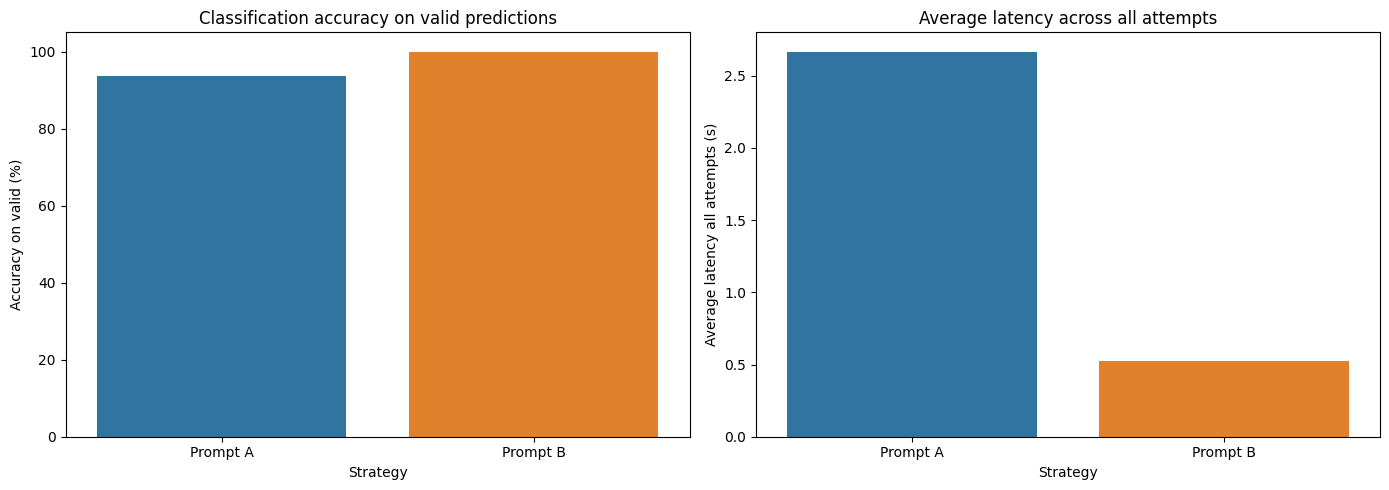

In [18]:
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
    classification_report
)

SENTIMENT_LABELS = ["Positive", "Negative", "Neutral", "Mixed"]
metrics_summary = []

for strategy in ["Prompt A", "Prompt B"]:
    df_strategy = df_results[df_results["prompt_strategy"] == strategy]
    df_valid = df_strategy[df_strategy["valid_schema"]]

    total_attempts = len(df_strategy)
    valid_count = len(df_valid)
    schema_rate = (valid_count / total_attempts * 100) if total_attempts else 0.0

    if valid_count:
        accuracy = accuracy_score(
            df_valid["expected_sentiment"],
            df_valid["predicted_sentiment"]
        ) * 100

        precision, recall, f1, _ = precision_recall_fscore_support(
            df_valid["expected_sentiment"],
            df_valid["predicted_sentiment"],
            labels=SENTIMENT_LABELS,
            average="macro",
            zero_division=0
        )
    else:
        accuracy = precision = recall = f1 = 0.0

    # Average latency includes all attempts, including failed calls.
    avg_latency = df_strategy["response_time"].mean() if total_attempts else 0.0

    metrics_summary.append({
        "Strategy": strategy,
        "Attempts": total_attempts,
        "Valid predictions": valid_count,
        "Schema validation rate (%)": round(schema_rate, 2),
        "Accuracy on valid (%)": round(accuracy, 2),
        "Macro precision": round(precision, 4),
        "Macro recall": round(recall, 4),
        "Macro F1": round(f1, 4),
        "Average latency all attempts (s)": round(avg_latency, 3)
    })

df_metrics = pd.DataFrame(metrics_summary)
display(df_metrics)

# Visual comparison using values calculated above.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(
    data=df_metrics, x="Strategy", y="Accuracy on valid (%)",
    hue="Strategy", legend=False, ax=axes[0]
)
axes[0].set_title("Classification accuracy on valid predictions")

sns.barplot(
    data=df_metrics, x="Strategy",
    y="Average latency all attempts (s)",
    hue="Strategy", legend=False, ax=axes[1]
)
axes[1].set_title("Average latency across all attempts")

plt.tight_layout()
plt.savefig("week9_prompt_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

### Metrics and chart output analysis
- **Schema validation rate:** Valid schema responses divided by all attempts.
- **Accuracy:** Correct sentiment predictions divided by schema-valid predictions.
- **Precision:** Of the predictions assigned to a class, how many were correct for that class.
- **Recall:** Of all actual examples of a class, how many were found.
- **F1-score:** Harmonic mean of precision and recall.
- **Macro average:** Calculate each class metric separately and give each class equal weight.
- **Latency:** Average time across all attempts, including failures.

The table reports the number of valid predictions so the classification-metric denominator is visible. A model can have a high schema rate but lower accuracy: valid JSON is not the same as correct sentiment.

The charts use values calculated from the actual evaluation results. Do not claim Prompt B is better unless the measured values support that conclusion.

## Confusion matrices and per-class reports

A confusion matrix compares the expected sentiment with the predicted sentiment:
- Rows represent expected (actual) labels.
- Columns represent predicted labels.
- Diagonal cells are correct predictions.
- Off-diagonal cells are misclassifications.

A false positive for a class is an example incorrectly assigned to that class. A false negative is an actual example of that class that was assigned somewhere else.

\n Prompt A


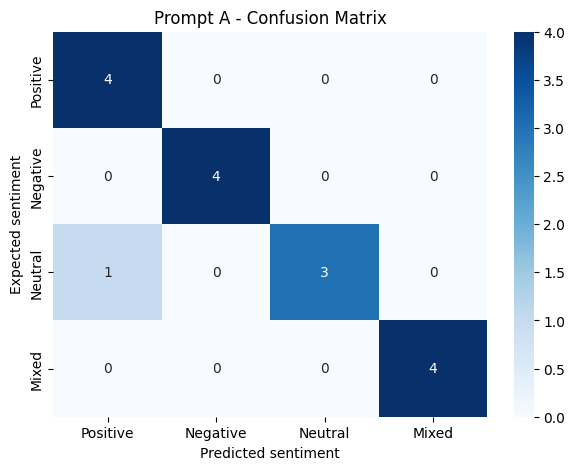

              precision    recall  f1-score   support

    Positive       0.80      1.00      0.89         4
    Negative       1.00      1.00      1.00         4
     Neutral       1.00      0.75      0.86         4
       Mixed       1.00      1.00      1.00         4

    accuracy                           0.94        16
   macro avg       0.95      0.94      0.94        16
weighted avg       0.95      0.94      0.94        16

\n Prompt B


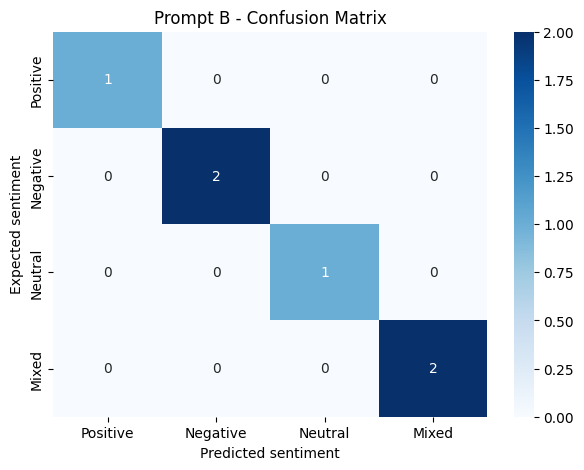

              precision    recall  f1-score   support

    Positive       1.00      1.00      1.00         1
    Negative       1.00      1.00      1.00         2
     Neutral       1.00      1.00      1.00         1
       Mixed       1.00      1.00      1.00         2

    accuracy                           1.00         6
   macro avg       1.00      1.00      1.00         6
weighted avg       1.00      1.00      1.00         6



In [19]:
SENTIMENT_LABELS = ["Positive", "Negative", "Neutral", "Mixed"]

for strategy in ["Prompt A", "Prompt B"]:
    group = df_results[
        (df_results["prompt_strategy"] == strategy) &
        (df_results["valid_schema"])
    ]

    print("\\n", strategy)

    if group.empty:
        print("No valid predictions; confusion matrix cannot be calculated.")
        continue

    cm = confusion_matrix(
        group["expected_sentiment"],
        group["predicted_sentiment"],
        labels=SENTIMENT_LABELS
    )

    plt.figure(figsize=(7, 5))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=SENTIMENT_LABELS,
        yticklabels=SENTIMENT_LABELS
    )
    plt.title(f"{strategy} - Confusion Matrix")
    plt.xlabel("Predicted sentiment")
    plt.ylabel("Expected sentiment")
    plt.show()

    print(classification_report(
        group["expected_sentiment"],
        group["predicted_sentiment"],
        labels=SENTIMENT_LABELS,
        zero_division=0
    ))

### Confusion-matrix output analysis

A number on the diagonal means the model predicted that class correctly. An off-diagonal number shows which sentiment was confused with another.

For example, a count in the `Mixed` expected row and `Negative` predicted column means a review labelled Mixed by the dataset was predicted as Negative. This is a false negative for Mixed and a false positive for Negative.

The classification report displays precision, recall, F1 and support for each sentiment. Support is the number of expected examples of that class among the schema-valid predictions.

In [25]:
# ============================================================
# INSPECT PROMPT B FAILURES
# ============================================================

import pandas as pd
import os

# 1. Load the saved failure log
failure_log = pd.read_csv("failure_log.csv")

# 2. Filter Prompt B failures using the correct column name
prompt_b_failures = failure_log[
    failure_log["prompt_strategy"] == "Prompt B"
]

# 3. Display the number of failures
print("Total Prompt B failures:", len(prompt_b_failures))

# 4. Display failure categories
print("\nFailure category counts:")

print(
    prompt_b_failures["failure_category"]
    .value_counts(dropna=False)
)

# 5. Display detailed failure information
print("\nDetailed Prompt B failures:")

display(
    prompt_b_failures[
        [
            "test_id",
            "expected_sentiment",
            "predicted_sentiment",
            "valid_schema",
            "failure_category",
            "error_message",
            "raw_response"
        ]
    ]
)

Total Prompt B failures: 14

Failure category counts:
failure_category
Rate limit or quota        13
Other API/runtime error     1
Name: count, dtype: int64

Detailed Prompt B failures:


,test_id,expected_sentiment,predicted_sentiment,valid_schema,failure_category,error_message,raw_response
4,4,Neutral,Unknown,False,Rate limit or quota,ClientError: 429 RESOURCE_EXHAUSTED. {'error':...,NaN
5,8,Positive,Unknown,False,Rate limit or quota,ClientError: 429 RESOURCE_EXHAUSTED. {'error':...,NaN
6,9,Neutral,Unknown,False,Rate limit or quota,ClientError: 429 RESOURCE_EXHAUSTED. {'error':...,NaN
7,10,Mixed,Unknown,False,Rate limit or quota,ClientError: 429 RESOURCE_EXHAUSTED. {'error':...,NaN
8,11,Neutral,Unknown,False,Rate limit or quota,ClientError: 429 RESOURCE_EXHAUSTED. {'error':...,NaN
9,12,Positive,Unknown,False,Rate limit or quota,ClientError: 429 RESOURCE_EXHAUSTED. {'error':...,NaN
10,13,Negative,Unknown,False,Other API/runtime error,ServerError: 503 UNAVAILABLE. {'error': {'code...,NaN
11,14,Negative,Unknown,False,Rate limit or quota,ClientError: 429 RESOURCE_EXHAUSTED. {'error':...,NaN
12,15,Mixed,Unknown,False,Rate limit or quota,ClientError: 429 RESOURCE_EXHAUSTED. {'error':...,NaN
13,16,Neutral,Unknown,False,Rate limit or quota,ClientError: 429 RESOURCE_EXHAUSTED. {'error':...,NaN


In [26]:
# ============================================================
# SEPARATE API FAILURES FROM SCHEMA FAILURES
# ============================================================

import pandas as pd

failure_log = pd.read_csv("failure_log.csv")

# Filter Prompt B records
prompt_b = failure_log[
    failure_log["prompt_strategy"] == "Prompt B"
]

# Identify API errors
api_error_mask = prompt_b["failure_category"].isin([
    "Rate limit or quota",
    "Other API/runtime error"
])

api_failures = prompt_b[api_error_mask]

# Identify genuine schema failures among received responses
schema_failures = prompt_b[
    (~prompt_b["valid_schema"].astype(bool))
    & (~api_error_mask)
]

print("PROMPT B FAILURE ANALYSIS")
print("=" * 45)

print("Total attempts:", len(prompt_b))
print("API failures:", len(api_failures))
print("Genuine schema failures:", len(schema_failures))

print(
    "Successful API responses:",
    len(prompt_b) - len(api_failures)
)

# Calculate schema validation rate among successful API responses
successful_api = prompt_b[~api_error_mask]

if len(successful_api) > 0:

    corrected_schema_rate = (
        successful_api["valid_schema"].astype(bool).mean() * 100
    )

    print(
        "\nSchema validation rate among successful API responses:",
        round(corrected_schema_rate, 2),
        "%"
    )

PROMPT B FAILURE ANALYSIS
Total attempts: 14
API failures: 14
Genuine schema failures: 0
Successful API responses: 0


## SECTION 14 – Prompt Improvement (Prompt C)

### Concept Explanation
Prompt improvement should be based on evidence from the previous evaluation. Inspect the actual misclassifications and technical failures. If a review with spelling mistakes was misclassified, an explicit spelling instruction may be useful. If a mixed review was assigned a single-sided sentiment, clarify the Mixed rule.

The Prompt C rules below test spelling, negation, mixed sentiment and neutral factual statements. If the earlier run did not show a particular failure, describe that rule as a robustness test rather than claiming it fixed an observed error.

In [20]:
prompt_c_system = '''
You are a careful customer review sentiment analyst.

Choose exactly one sentiment:
- Positive: praise or satisfaction only.
- Negative: criticism or dissatisfaction only.
- Neutral: factual wording without a clear opinion.
- Mixed: both praise and criticism.

Decision rules:
1. If both praise and criticism appear, choose Mixed.
2. Pay attention to negation, for example "not good" is Negative.
3. Correct obvious spelling mistakes internally when the intended word is clear.
4. Do not change the review meaning or invent details.
5. A factual delivery/receipt statement without opinion is Neutral.
6. Extract only aspects explicitly mentioned; use None when absent.
7. Return a response matching the supplied ReviewAnalysis schema.
'''

prompt_c_results = []

print("Evaluating Prompt C on the same 20 test cases...")
for _, row in df_tests.iterrows():
    p_data, valid, elapsed, err, raw = analyze_review(
        row["review"], prompt_c_system
    )

    prompt_c_results.append({
        "test_id": int(row["test_id"]),
        "prompt_strategy": "Prompt C",
        "review": row["review"],
        "expected_sentiment": row["expected_sentiment"],
        "predicted_sentiment": p_data.get("sentiment", "Unknown"),
        "confidence": p_data.get("confidence", None),
        "positive_aspect": p_data.get("positive_aspect", None),
        "negative_aspect": p_data.get("negative_aspect", None),
        "reason": p_data.get("reason", None),
        "valid_schema": valid,
        "response_time": elapsed,
        "error_message": err,
        "raw_response": raw
    })

df_prompt_c = pd.DataFrame(prompt_c_results)
df_all_results = pd.concat([df_results, df_prompt_c], ignore_index=True)

print("Prompt C attempts:", len(df_prompt_c))
print("Prompt C valid responses:", int(df_prompt_c["valid_schema"].sum()))
display(df_prompt_c.head())

Evaluating Prompt C on the same 20 test cases...
Prompt C attempts: 20
Prompt C valid responses: 17


,test_id,prompt_strategy,review,expected_sentiment,predicted_sentiment,confidence,positive_aspect,negative_aspect,reason,valid_schema,response_time,error_message,raw_response
0,1,Prompt C,I absolutely love this laptop! The screen is b...,Positive,Positive,1.0,screen clarity,NaN,The user expresses strong satisfaction with th...,True,2.097674,None,"{\n ""sentiment"": ""Positive"",\n ""confidence"":..."
1,2,Prompt C,Horrible experience. The screen was cracked on...,Negative,Negative,1.0,NaN,screen condition,The user explicitly describes the experience a...,True,2.542461,None,"{\n ""sentiment"": ""Negative"",\n ""confidence"":..."
2,3,Prompt C,The battery is amazing but the charging cord i...,Mixed,Mixed,1.0,battery,charging cord length,The user praises the battery performance while...,True,0.851977,None,"{\n ""sentiment"": ""Mixed"",\n ""confidence"": 1,..."
3,4,Prompt C,I received my order yesterday afternoon.,Neutral,Neutral,1.0,NaN,NaN,The statement is purely factual regarding the ...,True,0.711912,None,"{\n ""sentiment"": ""Neutral"",\n ""confidence"": ..."
4,5,Prompt C,"Lovve the color and shape, but it doesnt turn ...",Mixed,Mixed,1.0,color and shape,functionality,The user expresses satisfaction with the aesth...,True,2.976916,None,"{\n ""sentiment"": ""Mixed"",\n ""confidence"": 1,..."


### Prompt C output analysis
This cell makes 20 additional real API requests. Prompt C uses the same test reviews and expected labels as Prompt A and Prompt B. Its results are stored in `df_prompt_c`, and all three prompt results are combined in `df_all_results`.

Compare the actual Prompt C results with the earlier error table. Do not claim that Prompt C fixed a particular problem unless that problem was observed and the new results show improvement.

## SECTION 15 – Compare Prompt A, Prompt B and Prompt C

We calculate the same metrics for all three prompts. A good comparison considers schema validity, classification quality and latency together rather than selecting a prompt using only one score.

In [22]:
import os
all_metrics = []

for strategy in ["Prompt A", "Prompt B", "Prompt C"]:
    group = df_all_results[df_all_results["prompt_strategy"] == strategy]
    valid_group = group[group["valid_schema"]]
    attempts = len(group)
    valid_count = len(valid_group)

    schema_rate = valid_count / attempts * 100 if attempts else 0.0

    if valid_count:
        accuracy = accuracy_score(
            valid_group["expected_sentiment"],
            valid_group["predicted_sentiment"]
        ) * 100
        precision, recall, f1, _ = precision_recall_fscore_support(
            valid_group["expected_sentiment"],
            valid_group["predicted_sentiment"],
            labels=SENTIMENT_LABELS,
            average="macro",
            zero_division=0
        )
    else:
        accuracy = precision = recall = f1 = 0.0

    avg_latency = group["response_time"].mean() if attempts else 0.0

    all_metrics.append({
        "Strategy": strategy,
        "Attempts": attempts,
        "Valid predictions": valid_count,
        "Schema rate (%)": round(schema_rate, 2),
        "Accuracy on valid (%)": round(accuracy, 2),
        "Macro precision": round(precision, 4),
        "Macro recall": round(recall, 4),
        "Macro F1": round(f1, 4),
        "Average latency (s)": round(avg_latency, 3)
    })

df_all_metrics = pd.DataFrame(all_metrics)
display(df_all_metrics)

# Save final artifacts.
df_tests.to_csv("week9_test_dataset.csv", index=False)
df_all_results.to_csv("week9_evaluation_results.csv", index=False)
df_all_metrics.to_csv("week9_metrics_summary.csv", index=False)

all_failures = df_all_results[~df_all_results["valid_schema"]].copy()
if not all_failures.empty:
    all_failures["failure_category"] = all_failures["error_message"].apply(categorize_failure)
else:
    all_failures["failure_category"] = pd.Series(dtype="object")
all_failures.to_csv("failure_log.csv", index=False)

files_to_check = [
    "week9_test_dataset.csv",
    "week9_evaluation_results.csv",
    "week9_metrics_summary.csv",
    "failure_log.csv",
    "week9_prompt_comparison.png"
]

print("\nSaved-file verification:")
for filename in files_to_check:
    print(filename, "->", "FOUND" if os.path.exists(filename) else "NOT FOUND")

,Strategy,Attempts,Valid predictions,Schema rate (%),Accuracy on valid (%),Macro precision,Macro recall,Macro F1,Average latency (s)
0,Prompt A,20,16,80.0,93.75,0.95,0.9375,0.9365,2.667
1,Prompt B,20,6,30.0,100.00,1.00,1.0000,1.0000,0.526
2,Prompt C,20,17,85.0,94.12,0.95,0.9500,0.9444,12.898



Saved-file verification:
week9_test_dataset.csv -> FOUND
week9_evaluation_results.csv -> FOUND
week9_metrics_summary.csv -> FOUND
failure_log.csv -> FOUND
week9_prompt_comparison.png -> FOUND


### Code and output analysis
- The comparison table contains all three prompt strategies.
- Each prompt has 20 attempts when all loops complete.
- `week9_test_dataset.csv` stores the labelled test set.
- `week9_evaluation_results.csv` stores each individual attempt and its raw response.
- `week9_metrics_summary.csv` stores the metric comparison.
- `failure_log.csv` stores invalid API/schema responses.
- `week9_prompt_comparison.png` stores the Prompt A/B charts created earlier.

The files are stored in the Colab runtime. Download them before the runtime is deleted. The table contains actual run results; it is not prefilled with made-up values.

## SECTION 16 – Final project interpretation

### What the project demonstrates
The system combines prompt design, Gemini API requests, JSON structured output, Pydantic validation, labelled evaluation data, failure logging and prompt iteration.

### Important distinctions
- **Schema validity is not semantic correctness.** A response may satisfy the schema but classify the review incorrectly.
- **Confidence is not guaranteed calibration.** The model-generated confidence value should not be treated as a proven probability.
- **Prompt improvements need evidence.** Connect a prompt change to a specific observed failure or misclassification. If no such failure occurred, describe the rule as a robustness test rather than a proven fix.
- **The benchmark is small.** Twenty reviews are useful for learning but not enough to establish broad production performance.



## SECTION 17 – Viva questions and answers

1. **What is an LLM?** A large language model trained on large text collections to process and generate language.
2. **What is a token?** A piece of text processed by the model; it may be a word, part of a word or punctuation.
3. **What is Generative AI?** AI that creates content such as text, images, audio or code.
4. **What is prompt engineering?** Designing instructions and context to guide a model.
5. **What is zero-shot prompting?** Asking the model to perform a task without worked examples.
6. **What is few-shot prompting?** Supplying a small number of examples in the prompt.
7. **What is a system instruction?** High-level guidance about the model's role and behavior.
8. **What does temperature do?** It influences randomness in generated output.
9. **What is JSON?** A text format for representing structured data.
10. **What is a schema?** A definition of expected fields, types and constraints.
11. **What is Pydantic?** A Python library for parsing and validating data using typed models.
12. **What does `BaseModel` do?** It is the base class used to define a Pydantic model.
13. **What does `Literal` do?** It restricts a field to specified values.
14. **What does `Field(ge=0, le=1)` mean?** The value must be between 0 and 1 inclusive.
15. **JSON parsing vs Pydantic validation?** Parsing checks JSON syntax; Pydantic checks the data against the model.
16. **Can valid JSON still be wrong?** Yes, the sentiment can be incorrect even if the structure is valid.
17. **What is schema validation rate?** Valid schema responses divided by all attempts.
18. **What is accuracy?** Correct predictions divided by evaluated predictions.
19. **What is precision?** Of predictions assigned to a class, the proportion that are correct.
20. **What is recall?** Of actual examples of a class, the proportion correctly identified.
21. **What is F1-score?** The harmonic mean of precision and recall.
22. **What is macro averaging?** Giving each class equal weight when averaging its metric.
23. **What is a confusion matrix?** A table comparing expected and predicted labels.
24. **What is latency?** The elapsed time for a request.
25. **Why log raw responses?** To debug API, parsing and validation problems.
26. **Why store an API key in Colab Secrets?** To avoid exposing credentials in notebook source.
27. **Why discover models dynamically?** Model access and identifiers can differ by API key and change over time.
28. **Why use `try/except` in the analysis function?** To record errors and allow the evaluation loop to continue.
29. **Why use the same test cases for each prompt?** To make the comparison controlled and fair.
30. **What would you improve before production?** Use a larger labelled dataset, monitor costs and failures, test model versions, calibrate confidence and add human review for ambiguous cases.